# VNS y LNS: cambiar de vecindario y destruir/reparar

**Serie:** Metaheurísticas desde cero · Métodos de trayectoria · Notebook 04

Navegación: [← 03 Búsqueda local e ILS](03-busqueda-local-ils.ipynb) · [05 Aleatorizados y recocido simulado →](05-aleatorizados-recocido-simulado.ipynb)

## Contenido
1. Qué vas a aprender y prerrequisitos
2. Utilidades: instancia TSP, tours válidos
3. Estructuras de vecindario: swap, 2-opt, or-opt, 3-opt (con deltas y tamaños verificados)
4. Búsqueda local, óptimos locales y Variable Neighborhood Descent (VND)
5. Shaking (agitación) y Basic VNS
6. General VNS (GVNS)
7. Large Neighborhood Search (LNS): destruir y reparar
8. Adaptive LNS (ALNS): ruleta con puntajes
9. Comparación empírica sobre TSP
10. Ventajas y limitaciones, resumen, ejercicios, referencias

## 1. Qué vas a aprender y prerrequisitos

**Qué vas a aprender**
- Por qué un óptimo local *depende del vecindario* y cómo explotarlo: un punto que es óptimo para 2-opt puede no serlo para or-opt.
- Implementar cuatro vecindarios para TSP con **deltas incrementales** y verificar que coinciden con recalcular el costo completo.
- VND, Basic VNS y General VNS, incluyendo el papel del *shaking*.
- LNS: en lugar de mover un par de aristas, se *destruye* una parte grande de la solución y se *repara* con un constructivo.
- ALNS: elegir operadores de destrucción/reparación por ruleta con pesos que se actualizan según su desempeño.
- Comparar todo con semillas múltiples y reportar media ± desviación estándar, no una corrida afortunada.

**Prerrequisitos:** TSP y representación por permutación (ver la notebook de fundamentos), búsqueda local de primera mejora
(ver [03](03-busqueda-local-ils.ipynb)) y métodos constructivos como inserción más barata (ver [02](02-metodos-constructivos.ipynb)).
Para el criterio de aceptación que usaremos en LNS adelantamos el recocido simulado, que se deriva en
[05](05-aleatorizados-recocido-simulado.ipynb).

## 2. Utilidades: instancia, evaluación y validación

Usamos instancias euclídeas aleatorias en $[0,100]^2$. Guardamos la matriz de distancias como arreglo NumPy (`D`) y como lista de listas
(`d`): en bucles de Python puro indexar listas es bastante más rápido que indexar arreglos NumPy escalar a escalar.
Un tour es una lista de enteros que es una **permutación** de $0,\dots,n-1$; el tour es cíclico (la última ciudad conecta con la primera).

In [1]:
import time, math, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng_global = np.random.default_rng(2024)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

class TSP:
    '''Instancia euclídea aleatoria de n ciudades en [0,100]^2.'''
    def __init__(self, n, seed):
        rng = np.random.default_rng(seed)
        self.n = n
        self.xy = rng.random((n, 2)) * 100
        self.D = np.linalg.norm(self.xy[:, None, :] - self.xy[None, :, :], axis=2)
        self.d = self.D.tolist()          # copia en listas para bucles rápidos

    def largo(self, t):
        t = np.asarray(t)
        return float(self.D[t, np.roll(t, -1)].sum())

def es_tour(P, t):
    '''Verdadero si t es una permutación de 0..n-1.'''
    return len(t) == P.n and sorted(t) == list(range(P.n))

def graficar_tour(P, t, ax=None, titulo=""):
    ax = ax or plt.gca()
    t = list(t) + [t[0]]
    ax.plot(P.xy[t, 0], P.xy[t, 1], "-o", ms=4, lw=1.2)
    ax.set_title(f"{titulo}\nlargo = {P.largo(t[:-1]):.1f}")
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])

def vecino_mas_cercano(P, inicio=0):
    '''Constructivo: siempre ir a la ciudad no visitada más cercana.'''
    t, libres = [inicio], set(range(P.n)) - {inicio}
    while libres:
        ult = t[-1]
        prox = min(libres, key=lambda c: P.d[ult][c])
        t.append(prox); libres.remove(prox)
    return t

P0 = TSP(40, seed=1)
t_nn = vecino_mas_cercano(P0)
assert es_tour(P0, t_nn)
print("largo del tour de vecino más cercano:", round(P0.largo(t_nn), 2))

largo del tour de vecino más cercano: 584.26


## 3. Estructuras de vecindario

### Intuición
Un **vecindario** $N(x)$ es el conjunto de soluciones que se alcanzan desde $x$ con una modificación pequeña y bien definida.
Es como tener varios *tipos de lupa*: con una lupa ves los cambios de dos aristas, con otra ves reubicar un tramo. Una solución es
**óptimo local respecto a $N$** si ninguna solución en $N(x)$ es mejor. El hecho clave que sostiene toda la familia VNS:

> Un óptimo local respecto a un vecindario $N_1$ no tiene por qué serlo respecto a otro $N_2$, pero un óptimo **global** lo es respecto a *todos*.

### Los cuatro vecindarios que implementaremos (TSP simétrico, tour cíclico de $n$ ciudades)

| Vecindario | Movimiento | Aristas que cambian | Tamaño |
|---|---|---|---|
| **swap** (2-intercambio de posiciones) | intercambiar las ciudades en las posiciones $i<j$ | 4 (2 si son adyacentes) | $\binom{n}{2}$ |
| **2-opt** | invertir el tramo $t[i..j]$ | 2 | $\frac{n(n-3)}{2}$ |
| **or-opt** | mover un tramo de $L\in\{1,2,3\}$ ciudades a otra posición (con o sin invertirlo) | 3 | $\approx 5n^2$ |
| **3-opt (intercambio de segmentos)** | $A\,B\,C\,D \to A\,C\,B\,D$ | 3 | $\binom{n}{3}$ |

(En swap, si las ciudades son adyacentes cambian 2 aristas; si no, cambian 4.)

### Deltas incrementales
Evaluar un movimiento no requiere recalcular los $n$ términos del tour: basta con sumar las aristas nuevas y restar las eliminadas, $O(1)$.
Para 2-opt con $a=t[i-1],\ b=t[i],\ c=t[j],\ e=t[j+1]$:

$$\Delta_{2\text{-opt}} = d(a,c) + d(b,e) - d(a,b) - d(c,e).$$

Para el intercambio de segmentos con cortes en las aristas $(a,b),(c,d'),(e,f)$, donde $B=b\ldots c$ y $C=d'\ldots e$:

$$\Delta_{3\text{-opt}} = d(a,d') + d(e,b) + d(c,f) - d(a,b) - d(c,d') - d(e,f).$$

Cada vecindario se implementa como un *generador* de pares `(delta, movimiento)` más una función que **aplica** el movimiento.
Así podemos enumerarlo completo (para verificar deltas y tamaños) o tomar la primera mejora (para buscar).

In [2]:
EPS = 1e-9

# ---------- swap: intercambiar las ciudades en las posiciones i<j ----------
def delta_swap(P, t, i, j):
    d, n = P.d, P.n
    if j == i + 1 or (i == 0 and j == n - 1):          # adyacentes (cíclicamente)
        p = i if j == i + 1 else j                    # primera de las dos en el sentido del tour
        a, x, y, f = t[p - 1], t[p], t[(p + 1) % n], t[(p + 2) % n]
        return d[a][y] + d[x][f] - d[a][x] - d[y][f]
    a, x, c = t[i - 1], t[i], t[(i + 1) % n]
    q, y, f = t[j - 1], t[j], t[(j + 1) % n]
    return (d[a][y] + d[y][c] + d[q][x] + d[x][f]
            - d[a][x] - d[x][c] - d[q][y] - d[y][f])

def gen_swap(P, t):
    for i in range(P.n - 1):
        for j in range(i + 1, P.n):
            yield delta_swap(P, t, i, j), (i, j)

def apl_swap(t, mv):
    i, j = mv
    s = list(t); s[i], s[j] = s[j], s[i]
    return s

# ---------- 2-opt: invertir t[i..j] (1 <= i < j <= n-1) ----------
def gen_2opt(P, t):
    d, n = P.d, P.n
    for i in range(1, n - 1):
        a, b = t[i - 1], t[i]
        dab = d[a][b]
        for j in range(i + 1, n):
            if i == 1 and j == n - 1:      # degenerado: invierte todo menos t[0]
                continue
            c, e = t[j], t[(j + 1) % n]
            yield d[a][c] + d[b][e] - dab - d[c][e], (i, j)

def apl_2opt(t, mv):
    i, j = mv
    return t[:i] + t[i:j + 1][::-1] + t[j + 1:]

# ---------- or-opt: mover un tramo de L ciudades (con o sin invertir) ----------
def gen_oropt(P, t, Ls=(1, 2, 3)):
    d, n = P.d, P.n
    for L in Ls:
        for i in range(1, n - L):                   # el tramo es t[i:i+L], no envuelve
            a, s0, s1, b = t[i - 1], t[i], t[i + L - 1], t[i + L]
            quitar = d[a][b] - d[a][s0] - d[s1][b]
            for m in range(n - L):                  # insertar tras rest[m], con rest = t sin el tramo
                if m == i - 1:                      # posición original
                    continue
                p = t[m] if m < i else t[m + L]
                mq = (m + 1) % (n - L)
                q = t[mq] if mq < i else t[mq + L]
                base = quitar - d[p][q]
                yield base + d[p][s0] + d[s1][q], (L, i, m, False)
                if L > 1:
                    yield base + d[p][s1] + d[s0][q], (L, i, m, True)

def apl_oropt(t, mv):
    L, i, m, rev = mv
    seg = t[i:i + L]
    if rev: seg = seg[::-1]
    rest = t[:i] + t[i + L:]
    return rest[:m + 1] + seg + rest[m + 1:]

# ---------- 3-opt (intercambio de segmentos): A B C D -> A C B D ----------
def gen_3opt(P, t):
    d, n = P.d, P.n
    for i in range(1, n - 1):
        a, b = t[i - 1], t[i]
        for j in range(i + 1, n):
            c, dd = t[j - 1], t[j]
            ab_cd = d[a][b] + d[c][dd]
            for k in range(j + 1, n + 1):
                e, f = t[k - 1], t[k % n]
                yield d[a][dd] + d[e][b] + d[c][f] - ab_cd - d[e][f], (i, j, k)

def apl_3opt(t, mv):
    i, j, k = mv
    return t[:i] + t[j:k] + t[i:j] + t[k:]

VECINDARIOS = {
    "swap":   (gen_swap,   apl_swap),
    "2-opt":  (gen_2opt,   apl_2opt),
    "or-opt": (gen_oropt,  apl_oropt),
    "3-opt":  (gen_3opt,   apl_3opt),
}

### Verificación exhaustiva de deltas y de tamaños

Para varios tours aleatorios enumeramos **todos** los movimientos de cada vecindario y comprobamos tres cosas:
1. el resultado de aplicar el movimiento es una permutación válida;
2. el delta anunciado coincide con `largo(nuevo) - largo(actual)` calculado desde cero;
3. el número de movimientos coincide con la fórmula de la tabla (o es el esperado para or-opt).

In [3]:
def verificar_vecindarios(n=12, n_tours=5, seed=0):
    P = TSP(n, seed=seed)
    rng = np.random.default_rng(seed)
    errores = {k: 0.0 for k in VECINDARIOS}
    conteos = {k: set() for k in VECINDARIOS}
    for _ in range(n_tours):
        t = rng.permutation(n).tolist()
        L0 = P.largo(t)
        for nombre, (gen, apl) in VECINDARIOS.items():
            cnt = 0
            for delta, mv in gen(P, t):
                nuevo = apl(t, mv)
                assert es_tour(P, nuevo), (nombre, mv)
                errores[nombre] = max(errores[nombre], abs((P.largo(nuevo) - L0) - delta))
                cnt += 1
            conteos[nombre].add(cnt)
    return errores, {k: v.pop() for k, v in conteos.items()}

errores, conteos = verificar_vecindarios()
n = 12
formula = {
    "swap": n * (n - 1) // 2,
    "2-opt": n * (n - 3) // 2,
    "or-opt": sum((n - L - 1) ** 2 * (1 if L == 1 else 2) for L in (1, 2, 3)),
    "3-opt": math.comb(n, 3),
}
tabla = pd.DataFrame({"error máx. |delta - recálculo|": errores, "tamaño enumerado": conteos, "tamaño fórmula": formula})
print(tabla.to_string(float_format=lambda x: f"{x:.2e}"))
assert all(e < 1e-9 for e in errores.values()) and conteos == formula
print("\nTodos los deltas coinciden con la recomputación y los tamaños con las fórmulas (n = 12).")

        error máx. |delta - recálculo|  tamaño enumerado  tamaño fórmula
swap                          2.27e-13                66              66
2-opt                         2.13e-13                54              54
or-opt                        2.42e-13               390             390
3-opt                         2.42e-13               220             220

Todos los deltas coinciden con la recomputación y los tamaños con las fórmulas (n = 12).


Los deltas son exactos (error de redondeo ~$10^{-14}$) y los tamaños enumerados coinciden con las fórmulas.
Fíjate en el crecimiento: para $n=40$ el vecindario or-opt tiene unos pocos miles de vecinos, 2-opt unos 700 y 3-opt casi 10 000.
Más grande no significa mejor: cuesta más explorarlo, así que el orden en que se usan importa (siguiente sección).

Tamaños para n=40:  swap=780,  2-opt=740,  or-opt=6774,  3-opt=9880


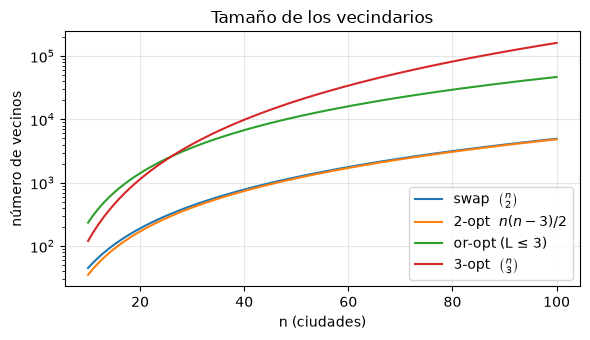

In [4]:
n = 40
print(f"Tamaños para n={n}:  swap={n*(n-1)//2},  2-opt={n*(n-3)//2},  "
      f"or-opt={sum((n-L-1)**2*(1 if L==1 else 2) for L in (1,2,3))},  3-opt={math.comb(n,3)}")
fig, ax = plt.subplots(figsize=(6, 3.5))
ns = np.arange(10, 101)
ax.plot(ns, ns*(ns-1)/2, label="swap  $\\binom{n}{2}$")
ax.plot(ns, ns*(ns-3)/2, label="2-opt  $n(n-3)/2$")
ax.plot(ns, [sum((k-L-1)**2*(1 if L==1 else 2) for L in (1,2,3)) for k in ns], label="or-opt (L ≤ 3)")
ax.plot(ns, [math.comb(int(k), 3) for k in ns], label="3-opt  $\\binom{n}{3}$")
ax.set_yscale("log"); ax.set_xlabel("n (ciudades)"); ax.set_ylabel("número de vecinos")
ax.set_title("Tamaño de los vecindarios"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Búsqueda local y Variable Neighborhood Descent (VND)

### Búsqueda local de primera mejora
Dado un vecindario, recorremos sus movimientos y aplicamos el **primero** con $\Delta<0$; repetimos hasta que ninguno mejora.
El resultado es un óptimo local respecto a ese vecindario.

### VND
VND explota que **un óptimo local de $N_k$ puede no serlo de $N_{k+1}$**. Dada una lista ordenada de vecindarios $N_1,\dots,N_{k_{\max}}$
(típicamente de menor a mayor costo):

```
VND(x, N_1..N_kmax):
    k = 1
    mientras k <= kmax:
        buscar x' = mejor/primer vecino de x en N_k   (mejora)
        si f(x') < f(x):  x = x';  k = 1      # al mejorar se vuelve al vecindario más barato
        si no:            k = k + 1
    devolver x                                 # óptimo local respecto a TODOS los N_k
```

El resultado es óptimo local respecto a **todos** los vecindarios de la lista simultáneamente, lo que es una condición más fuerte que ser óptimo de uno solo.

inicial 2162.6 | 2-opt: 535.2 | VND(or-opt,2-opt,3-opt): 498.0


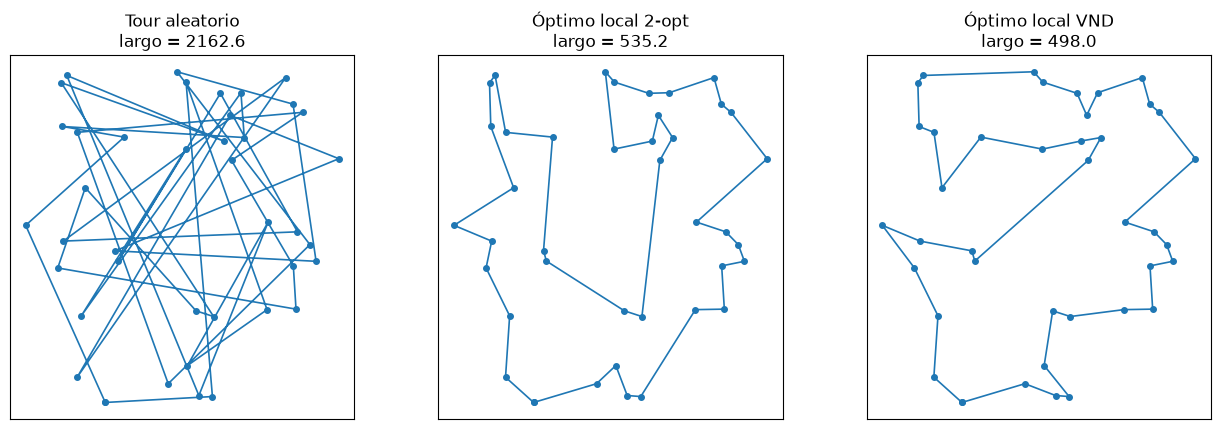

In [5]:
def paso_mejora(P, t, nombre):
    '''Primer movimiento con delta < 0 en el vecindario `nombre`; None si t es óptimo local de él.'''
    gen, apl = VECINDARIOS[nombre]
    for delta, mv in gen(P, t):
        if delta < -EPS:
            return delta, apl(t, mv)
    return None

def busqueda_local(P, t, nombre, L=None):
    '''Descenso de primera mejora en un único vecindario. Devuelve (tour, largo).'''
    L = P.largo(t) if L is None else L
    while True:
        r = paso_mejora(P, t, nombre)
        if r is None:
            return t, L
        L += r[0]; t = r[1]

def vnd(P, t, orden, L=None):
    '''Variable Neighborhood Descent sobre la lista `orden` de vecindarios.'''
    L = P.largo(t) if L is None else L
    k = 0
    while k < len(orden):
        r = paso_mejora(P, t, orden[k])
        if r is not None:
            L += r[0]; t = r[1]; k = 0
        else:
            k += 1
    return t, L

# Demostración: desde un tour aleatorio
rng = np.random.default_rng(5)
t_ini = rng.permutation(P0.n).tolist()
t_a, L_a = busqueda_local(P0, t_ini, "2-opt")
t_b, L_b = vnd(P0, t_ini, ["or-opt", "2-opt", "3-opt"])
assert es_tour(P0, t_a) and es_tour(P0, t_b)
assert abs(L_a - P0.largo(t_a)) < 1e-6 and abs(L_b - P0.largo(t_b)) < 1e-6   # largo incremental == recalculado
print(f"inicial {P0.largo(t_ini):.1f} | 2-opt: {L_a:.1f} | VND(or-opt,2-opt,3-opt): {L_b:.1f}")

fig, axs = plt.subplots(1, 3, figsize=(13, 4.3))
graficar_tour(P0, t_ini, axs[0], "Tour aleatorio")
graficar_tour(P0, t_a, axs[1], "Óptimo local 2-opt")
graficar_tour(P0, t_b, axs[2], "Óptimo local VND")
plt.tight_layout(); plt.show()

### Un óptimo local de un vecindario no lo es de otro (verificación)

Tomamos óptimos locales de 2-opt desde muchos tours aleatorios y contamos cuántos **no** son óptimos locales de or-opt, y viceversa.
Si la fracción es alta, hay mucho que ganar combinando vecindarios.

In [6]:
rng = np.random.default_rng(11)
n_s = 30
cont = {("2-opt", "or-opt"): 0, ("or-opt", "2-opt"): 0, ("2-opt", "3-opt"): 0}
for _ in range(n_s):
    t0 = rng.permutation(P0.n).tolist()
    opt2, _ = busqueda_local(P0, t0, "2-opt")
    optor, _ = busqueda_local(P0, t0, "or-opt")
    cont[("2-opt", "or-opt")] += paso_mejora(P0, opt2, "or-opt") is not None
    cont[("or-opt", "2-opt")] += paso_mejora(P0, optor, "2-opt") is not None
    cont[("2-opt", "3-opt")] += paso_mejora(P0, opt2, "3-opt") is not None
print(f"Sobre {n_s} óptimos locales (n={P0.n}):")
for (a, b), c in cont.items():
    print(f"  óptimo de {a:6s} que se puede mejorar con {b:6s}: {c}/{n_s} = {c/n_s:.0%}")

Sobre 30 óptimos locales (n=40):
  óptimo de 2-opt  que se puede mejorar con or-opt: 26/30 = 87%
  óptimo de or-opt que se puede mejorar con 2-opt : 24/30 = 80%
  óptimo de 2-opt  que se puede mejorar con 3-opt : 27/30 = 90%


### Efecto del orden y de la composición del VND

Comparamos, desde los mismos 25 tours aleatorios, el largo final y el tiempo de: cada vecindario solo, y VND con distintos órdenes.
El orden "de barato a caro" suele ser la recomendación, porque los vecindarios caros solo se exploran cuando los baratos ya no mejoran.

In [7]:
configs = {
    "2-opt solo":              ["2-opt"],
    "or-opt solo":             ["or-opt"],
    "3-opt solo":              ["3-opt"],
    "VND 2-opt → or-opt":      ["2-opt", "or-opt"],
    "VND or-opt → 2-opt":      ["or-opt", "2-opt"],
    "VND 2-opt → or-opt → 3-opt": ["2-opt", "or-opt", "3-opt"],
    "VND 3-opt → or-opt → 2-opt": ["3-opt", "or-opt", "2-opt"],
}
rng = np.random.default_rng(21)
starts = [rng.permutation(P0.n).tolist() for _ in range(25)]
filas = []
for nombre, orden in configs.items():
    Ls, tiempos = [], []
    for t0 in starts:
        c0 = time.perf_counter()
        t_fin, L = vnd(P0, t0, orden)
        tiempos.append(time.perf_counter() - c0)
        assert es_tour(P0, t_fin)
        Ls.append(L)
    filas.append((nombre, np.mean(Ls), np.std(Ls, ddof=1), np.min(Ls), np.mean(tiempos) * 1000))
df_vnd = pd.DataFrame(filas, columns=["configuración", "largo medio", "desv. est.", "mejor", "ms por corrida"]).set_index("configuración")
print(df_vnd.round(2).to_string())

                            largo medio  desv. est.   mejor  ms por corrida
configuración                                                              
2-opt solo                       485.14       26.26  465.06            2.08
or-opt solo                      519.66       41.46  465.06            9.08
3-opt solo                       488.65       25.61  465.06           21.31
VND 2-opt → or-opt               470.12        9.39  465.06            3.34
VND or-opt → 2-opt               487.23       22.41  465.06           10.64
VND 2-opt → or-opt → 3-opt       469.63        9.32  465.06            4.16
VND 3-opt → or-opt → 2-opt       477.17       17.63  465.06           24.56


Lectura de la tabla (las medias de esta corrida; lo que importa es la comparación entre filas): combinar vecindarios produce óptimos locales mejores y más estables (menor desviación) que cualquiera de ellos por separado.
El **orden** también importa, tanto en tiempo como en calidad media, porque rutas de descenso distintas terminan en óptimos locales distintos: empezar por el vecindario más barato y rápido (2-opt) fue mejor y más rápido que empezar por or-opt o por 3-opt.
Pero ningún VND garantiza el óptimo global: nos deja atascados en un óptimo local respecto a la **unión** de vecindarios. Para escapar necesitamos *shaking*.

## 5. Shaking y Basic VNS

### Idea
VNS (Mladenović y Hansen, 1997) se apoya en tres hechos: (i) un mínimo local respecto a un vecindario no lo es necesariamente respecto a otro;
(ii) un mínimo global lo es respecto a todos; (iii) los mínimos locales de un problema suelen estar *cerca* unos de otros.
Por (iii), tiene sentido explorar **alrededor** del óptimo local actual, aumentando progresivamente la distancia.

### Shaking
Definimos una familia de vecindarios de perturbación $\mathcal{N}_1,\dots,\mathcal{N}_{k_{\max}}$ con $\mathcal{N}_k(x)$ = conjunto de soluciones a "distancia $k$" de $x$.
El **shaking** elige un $x'\in\mathcal{N}_k(x)$ *al azar*. Aquí $\mathcal{N}_k$ = aplicar $k$ swaps aleatorios consecutivos. Hay dos requisitos prácticos:
- debe ser **aleatorio** (si fuera determinista, repetiríamos el mismo salto);
- no debe poder **deshacerse** con un solo paso de la búsqueda local posterior; por eso no agitamos con 2-opt cuando la búsqueda local es 2-opt.

### Basic VNS (pseudocódigo)
```
BasicVNS(x):
    x = LS(x)
    mientras no se agote el presupuesto:
        k = 1
        mientras k <= kmax:
            x' = shake(x, k)              # aleatorio en N_k(x)
            x'' = LS(x')                  # búsqueda local
            si f(x'') < f(x):  x = x'';  k = 1     # mover y volver al vecindario más cercano
            si no:             k = k + 1           # alejarse
    devolver x
```

In [8]:
def shake(t, k, rng):
    '''k swaps aleatorios consecutivos (perturbación de 'intensidad' k).'''
    t = list(t)
    n = len(t)
    for _ in range(k):
        i, j = rng.choice(n, 2, replace=False)
        t[i], t[j] = t[j], t[i]
    return t

# Diagnóstico: ¿con qué frecuencia la búsqueda local deshace el shaking?
def diagnostico_shaking(P, ls, kmax=8, reps=60, seed=3):
    rng = np.random.default_rng(seed)
    base, Lb = ls(P, vecino_mas_cercano(P))
    res = []
    for k in range(1, kmax + 1):
        vuelve, Ls = 0, []
        for _ in range(reps):
            x, L = ls(P, shake(base, k, rng))
            vuelve += (L > Lb - 1e-7 and L < Lb + 1e-7)
            Ls.append(L)
        res.append((k, vuelve / reps, np.median(Ls) - Lb, np.min(Ls) - Lb))
    return pd.DataFrame(res, columns=["k", "frac. vuelve al mismo largo", "Δ mediana vs base", "Δ mejor vs base"]).set_index("k")

ls_2opt = lambda P, t: busqueda_local(P, t, "2-opt")
print("Búsqueda local = 2-opt, shaking = k swaps aleatorios")
print(diagnostico_shaking(P0, ls_2opt).round(3).to_string())

Búsqueda local = 2-opt, shaking = k swaps aleatorios


   frac. vuelve al mismo largo  Δ mediana vs base  Δ mejor vs base
k                                                                 
1                        0.800              0.000            -4.19
2                        0.717              0.000            -4.19
3                        0.500              0.000            -4.19
4                        0.350              1.843            -4.19
5                        0.233              3.018            -4.19
6                        0.133             11.394            -4.19
7                        0.150              5.555            -4.19
8                        0.217              5.684            -4.19


Con $k$ pequeño la búsqueda local vuelve al **mismo óptimo local** la mayor parte de las veces (la primera columna): el shaking es demasiado débil y la iteración se desperdicia.
A medida que $k$ crece, esa fracción baja y la mediana del largo se aleja del óptimo base (más diversificación, pero un punto de partida peor para la búsqueda local; la columna "Δ mejor" muestra que, de todos modos,
entre las repeticiones aparece alguna mejora respecto de la base, que es lo que VNS captura). VNS gestiona esta tensión *adaptando $k$ automáticamente*:
empieza con $k=1$ y solo aumenta cuando no hay mejora.

Antes de implementar las metaheurísticas, definimos una interfaz común: cada método recibe la instancia, un generador aleatorio y un **presupuesto en segundos**,
y devuelve el mejor tour, su largo y la historia `(tiempo, mejor_largo)` para trazar curvas de convergencia anytime.

In [9]:
class Reloj:
    '''Presupuesto de tiempo + registro de la mejor solución a lo largo del tiempo.'''
    def __init__(self, presupuesto):
        self.t0 = time.perf_counter(); self.pres = presupuesto
        self.mejor = float("inf"); self.hist = []
    def agotado(self):
        return time.perf_counter() - self.t0 >= self.pres
    def frac(self):
        return min(1.0, (time.perf_counter() - self.t0) / self.pres)
    def registrar(self, L):
        if L < self.mejor - 1e-9:
            self.mejor = L; self.hist.append((time.perf_counter() - self.t0, L))

def multistart_2opt(P, rng, presupuesto):
    '''Línea base: reinicios aleatorios + 2-opt.'''
    rel = Reloj(presupuesto); mejor_t = None
    while not rel.agotado():
        t, L = busqueda_local(P, rng.permutation(P.n).tolist(), "2-opt")
        if L < rel.mejor - 1e-9: mejor_t = t
        rel.registrar(L)
    return mejor_t, rel.mejor, rel.hist

def basic_vns(P, rng, presupuesto, kmax=6):
    '''Basic VNS: shaking = k swaps; búsqueda local = 2-opt (un solo vecindario).'''
    rel = Reloj(presupuesto)
    x, Lx = busqueda_local(P, vecino_mas_cercano(P, int(rng.integers(P.n))), "2-opt")
    rel.registrar(Lx)
    while not rel.agotado():
        k = 1
        while k <= kmax and not rel.agotado():
            x2, L2 = busqueda_local(P, shake(x, k, rng), "2-opt")
            if L2 < Lx - 1e-9:
                x, Lx = x2, L2; k = 1; rel.registrar(Lx)
            else:
                k += 1
    return x, Lx, rel.hist

t, L, h = basic_vns(P0, np.random.default_rng(0), 1.0)
assert es_tour(P0, t) and abs(P0.largo(t) - L) < 1e-6
print(f"Basic VNS (1 s): largo = {L:.2f}; mejoras registradas: {len(h)}")

Basic VNS (1 s): largo = 465.06; mejoras registradas: 2


## 6. General VNS (GVNS)

GVNS sustituye la búsqueda local simple por un **VND**, que es lo que ya implementamos. El shaking sigue siendo aleatorio y la regla de
aceptación es la misma. En la práctica es la variante más usada: el VND aporta *intensificación* fuerte y el shaking aporta *diversificación* controlada.
Existen otras variantes (Hansen, Mladenović y Pérez, 2010):

| Variante | Qué cambia |
|---|---|
| **VND** | Sin shaking; solo cambio sistemático de vecindario de *descenso* |
| **RVNS** (reduced) | Sin búsqueda local: solo shaking + aceptar si mejora (útil en instancias enormes) |
| **Basic VNS** | Shaking + búsqueda local en un vecindario |
| **GVNS** | Shaking + VND como búsqueda local |
| **Skewed VNS** | Acepta soluciones algo peores si están lo bastante *lejos* de la actual (explora valles lejanos) |

Para GVNS usamos $\text{VND}=[\text{or-opt},\text{2-opt},\text{3-opt}]$ y $k_{\max}=6$.

In [10]:
def gvns(P, rng, presupuesto, kmax=6, orden=("or-opt", "2-opt", "3-opt")):
    '''General VNS: shaking de k swaps + VND como búsqueda local.'''
    rel = Reloj(presupuesto)
    x, Lx = vnd(P, vecino_mas_cercano(P, int(rng.integers(P.n))), list(orden))
    rel.registrar(Lx)
    while not rel.agotado():
        k = 1
        while k <= kmax and not rel.agotado():
            x2, L2 = vnd(P, shake(x, k, rng), list(orden))
            if L2 < Lx - 1e-9:
                x, Lx = x2, L2; k = 1; rel.registrar(Lx)
            else:
                k += 1
    return x, Lx, rel.hist

t, L, h = gvns(P0, np.random.default_rng(0), 1.0)
assert es_tour(P0, t) and abs(P0.largo(t) - L) < 1e-6
print(f"GVNS (1 s): largo = {L:.2f}; mejoras registradas: {len(h)}")

GVNS (1 s): largo = 465.06; mejoras registradas: 2


## 7. Large Neighborhood Search (LNS): destruir y reparar

### Intuición
Los vecindarios clásicos (2-opt, or-opt) cambian 2-3 aristas. LNS (Shaw, 1998) usa un vecindario **enorme** definido implícitamente por un par de operadores:

1. **Destruir**: se quitan $q$ ciudades de la solución (por ejemplo, las que están cerca unas de otras).
2. **Reparar**: se reinsertan las ciudades quitadas con un método constructivo (inserción más barata, con arrepentimiento...).

Es como retirar un tramo de fichas de un rompecabezas y volver a armarlo bien, en vez de intercambiar dos fichas. El vecindario resultante contiene
todas las soluciones que el reparador puede producir tras la destrucción, un conjunto exponencialmente grande que no se puede enumerar pero sí *muestrear*.

### Operadores de destrucción (elegimos tres)
- **Aleatorio**: quitar $q$ ciudades al azar (diversifica).
- **Peor**: quitar las ciudades cuya remoción ahorra más, $\text{ahorro}(c)=d(\text{prev},c)+d(c,\text{sig})-d(\text{prev},\text{sig})$, con aleatorización $\lfloor |S|\,u^{p}\rfloor$, $u\sim U(0,1)$, para no ser determinista.
- **Relacionado** (Shaw): partir de una ciudad semilla y quitar ciudades *cercanas* a las ya quitadas; reinsertarlas juntas permite reorganizar una zona completa.

### Operadores de reparación (elegimos dos)
- **Inserción voraz**: repetidamente insertar la (ciudad, posición) de menor costo $\Delta=d(u,c)+d(c,v)-d(u,v)$.
- **Arrepentimiento-2**: elegir primero la ciudad con mayor *arrepentimiento* $r(c)=\Delta_2(c)-\Delta_1(c)$ (diferencia entre su segunda mejor y mejor posición), pues es la que más pierde si se la deja para después.

### Criterio de aceptación
Aceptamos la nueva solución $x'$ si mejora o, si no, con probabilidad $e^{-(f(x')-f(x))/T}$ (criterio de recocido simulado, derivado en la
[notebook 05](05-aleatorizados-recocido-simulado.ipynb)), con $T$ decreciendo geométricamente en el tiempo. Guardamos siempre la mejor solución global.
Con $T=0$ sería un descenso puro.

### Pseudocódigo
```
LNS(x):  x_mejor = x
    mientras no se agote el presupuesto:
        q  = entero aleatorio en [q_min, q_max]
        (x_parcial, quitadas) = destruir(x, q)
        x' = reparar(x_parcial, quitadas)
        si aceptar(x', x, T):  x = x'
        si f(x') < f(x_mejor): x_mejor = x'
        T = T * enfriamiento
```

Los 6 pares destruir/reparar producen tours válidos.


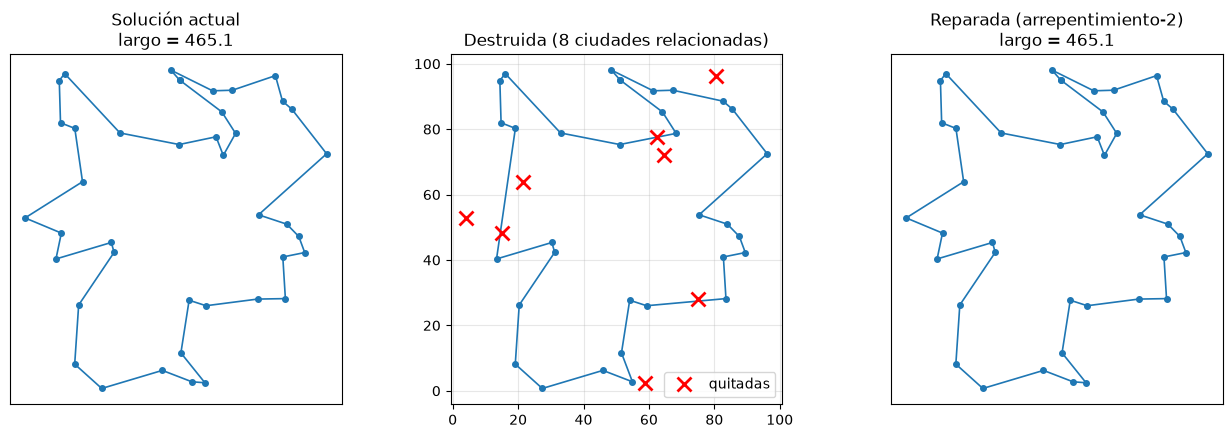

In [11]:
# ---------------- operadores de destrucción: (P, t, q, rng) -> (parcial, quitadas) ----------------
def _sel_sesgada(n_items, rng, p):
    return min(int(n_items * rng.random() ** p), n_items - 1)

def destruir_aleatorio(P, t, q, rng):
    quitadas = rng.choice(t, q, replace=False).tolist()
    s = set(quitadas)
    return [c for c in t if c not in s], quitadas

def destruir_peor(P, t, q, rng, p=3.0):
    d, parcial, quitadas = P.d, list(t), []
    for _ in range(q):
        m = len(parcial)
        ahorro = [d[parcial[i - 1]][parcial[i]] + d[parcial[i]][parcial[(i + 1) % m]]
                  - d[parcial[i - 1]][parcial[(i + 1) % m]] for i in range(m)]
        orden = np.argsort(ahorro)[::-1]                 # mayor ahorro primero
        i = int(orden[_sel_sesgada(m, rng, p)])
        quitadas.append(parcial.pop(i))
    return parcial, quitadas

def destruir_relacionado(P, t, q, rng, p=3.0):
    semilla = int(rng.choice(t))
    quitadas, resto = [semilla], set(t) - {semilla}
    while len(quitadas) < q:
        ref = quitadas[int(rng.integers(len(quitadas)))]
        cand = sorted(resto, key=lambda c: P.d[ref][c])  # más cercanas a ref primero
        c = cand[_sel_sesgada(len(cand), rng, p)]
        quitadas.append(c); resto.remove(c)
    s = set(quitadas)
    return [c for c in t if c not in s], quitadas

# ---------------- operadores de reparación: (P, parcial, quitadas, rng) -> tour completo ----------------
def _matriz_costos(P, parcial, restantes):
    '''costo[c, m] = costo de insertar restantes[c] entre parcial[m] y parcial[m+1].'''
    p = np.array(parcial); nxt = np.roll(p, -1)
    r = np.array(restantes)
    return P.D[np.ix_(r, p)] + P.D[np.ix_(r, nxt)] - P.D[p, nxt][None, :]

def reparar_voraz(P, parcial, quitadas, rng=None):
    parcial, rest = list(parcial), list(quitadas)
    while rest:
        C = _matriz_costos(P, parcial, rest)
        c, m = np.unravel_index(np.argmin(C), C.shape)
        parcial.insert(int(m) + 1, rest.pop(int(c)))
    return parcial

def reparar_arrepentimiento(P, parcial, quitadas, rng=None):
    parcial, rest = list(parcial), list(quitadas)
    while rest:
        C = _matriz_costos(P, parcial, rest)
        if C.shape[1] >= 2:
            dos = np.partition(C, 1, axis=1)[:, :2]
            arrep = dos[:, 1] - dos[:, 0]
        else:
            arrep = np.zeros(C.shape[0])
        mejor = C.min(axis=1)
        c = int(np.lexsort((mejor, -arrep))[0])          # mayor arrepentimiento; desempate por menor costo
        m = int(np.argmin(C[c]))
        parcial.insert(m + 1, rest.pop(c))
    return parcial

DESTRUIR = {"aleatorio": destruir_aleatorio, "peor": destruir_peor, "relacionado": destruir_relacionado}
REPARAR = {"voraz": reparar_voraz, "arrepentimiento": reparar_arrepentimiento}

# Validación: todos los pares destruir/reparar devuelven un tour válido con las ciudades quitadas reinsertadas
rng = np.random.default_rng(9)
for nd, fd in DESTRUIR.items():
    for nr, fr in REPARAR.items():
        for _ in range(30):
            t = rng.permutation(P0.n).tolist(); q = int(rng.integers(2, 12))
            parcial, quit_ = fd(P0, t, q, rng)
            assert len(quit_) == q and len(parcial) == P0.n - q and not (set(parcial) & set(quit_))
            assert es_tour(P0, fr(P0, parcial, quit_, rng)), (nd, nr)
print("Los 6 pares destruir/reparar producen tours válidos.")

# Ilustración: destruir de forma 'relacionada' y reparar
t_demo, _ = vnd(P0, vecino_mas_cercano(P0), ["2-opt", "or-opt"])
parcial, quit_ = destruir_relacionado(P0, t_demo, 8, np.random.default_rng(4))
rep = reparar_arrepentimiento(P0, parcial, quit_)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.3))
graficar_tour(P0, t_demo, axs[0], "Solución actual")
tp = parcial + [parcial[0]]
axs[1].plot(P0.xy[tp, 0], P0.xy[tp, 1], "-o", ms=4, lw=1.2)
axs[1].plot(P0.xy[quit_, 0], P0.xy[quit_, 1], "rx", ms=10, mew=2, label="quitadas")
axs[1].set_title("Destruida (8 ciudades relacionadas)"); axs[1].legend(); axs[1].set_aspect("equal")
graficar_tour(P0, rep, axs[2], "Reparada (arrepentimiento-2)")
plt.tight_layout(); plt.show()

### Implementación de LNS (y de ALNS)

Escribimos un único motor que recibe la lista de operadores y un indicador `adaptativo`:
- con **un** par fijo (aleatorio + voraz, por ejemplo) y sin adaptación es LNS clásico;
- con todos los operadores y pesos adaptativos es ALNS (siguiente sección).

El motor mantiene la solución actual, la mejor global, el historial y (si es adaptativo) los pesos de los operadores.

## 8. Adaptive LNS (ALNS): selección adaptativa con ruleta

Con varios operadores disponibles no sabemos de antemano cuál conviene, y puede cambiar a lo largo de la búsqueda (los destructivos aleatorios rinden al inicio; los refinados, al final).
Ropke y Pisinger (2006) proponen **aprender** qué operador usar:

1. A cada operador $i$ se le asigna un peso $w_i$ (inicialmente 1). Se elige por **ruleta**: $P(i)=\dfrac{w_i}{\sum_j w_j}$ (destructor y reparador por separado).
2. Tras cada iteración se otorga un puntaje al operador usado según el resultado:
   - $\sigma_1$: la nueva solución es la **mejor global** hasta ahora;
   - $\sigma_2$: mejora la solución actual (no necesariamente la mejor);
   - $\sigma_3$: es **aceptada** aunque sea peor.

   con $\sigma_1>\sigma_3>\sigma_2$ en nuestra configuración (33, 9, 13; son valores típicos de la literatura y son configurables).
3. Cada **segmento** de $\theta$ iteraciones se actualizan los pesos con una media móvil exponencial:
$$ w_i \leftarrow (1-\rho)\,w_i + \rho\,\frac{\pi_i}{\max(1,a_i)}, $$
donde $\pi_i$ es el puntaje acumulado en el segmento, $a_i$ cuántas veces se usó y $\rho\in[0,1]$ el **factor de reacción** (0 = nunca aprende; 1 = solo cuenta el último segmento).
Los puntajes se reinician en cada segmento.

Ventaja: el algoritmo se autoconfigura; la mezcla de operadores se adapta a la instancia y a la fase de búsqueda. Costo: más parámetros ($\sigma$, $\rho$, $\theta$) que, irónicamente, también hay que ajustar
(ver la notebook de [ajuste de parámetros](../05-evaluacion-y-ajuste/15-ajuste-de-parametros.ipynb)).

In [12]:
def alns(P, rng, presupuesto, destructores=None, reparadores=None, adaptativo=True,
         q_rango=(0.05, 0.25), sigma=(33, 9, 13), rho=0.1, theta=50,
         aceptar_peor=0.03, T_final_rel=0.01, ls_inicial=True):
    '''
    ALNS / LNS para TSP.
      - destructores / reparadores: listas de nombres (claves de DESTRUIR / REPARAR).
      - adaptativo=False: selección uniforme y sin pesos (LNS clásico con los operadores dados).
      - aceptación tipo recocido: T0 tal que una solución 'aceptar_peor' (fracción del largo)
        peor se acepta con prob. 0.5; T decae geométricamente con el tiempo hasta T0*T_final_rel.
    Devuelve (mejor_tour, mejor_largo, hist, info) con info = trazas de pesos y uso de operadores.
    '''
    nd = destructores or list(DESTRUIR); nr = reparadores or list(REPARAR)
    rel = Reloj(presupuesto)
    t = vecino_mas_cercano(P, int(rng.integers(P.n)))
    L = P.largo(t)
    if ls_inicial:
        t, L = busqueda_local(P, t, "2-opt", L)
    mejor_t, mejor_L = t, L
    rel.registrar(L)
    T0 = -aceptar_peor * L / math.log(0.5)
    wd, wr = np.ones(len(nd)), np.ones(len(nr))
    pd_, pr_ = np.zeros(len(nd)), np.zeros(len(nr))          # puntajes del segmento
    ad, ar = np.zeros(len(nd)), np.zeros(len(nr))            # usos en el segmento
    uso_total_d = np.zeros(len(nd), int); uso_total_r = np.zeros(len(nr), int)
    traza_w = []; it = 0
    q_min, q_max = max(2, int(q_rango[0] * P.n)), max(3, int(q_rango[1] * P.n))
    while not rel.agotado():
        it += 1
        T = T0 * (T_final_rel ** rel.frac())
        if adaptativo:
            i = rng.choice(len(nd), p=wd / wd.sum()); j = rng.choice(len(nr), p=wr / wr.sum())
        else:
            i = int(rng.integers(len(nd))); j = int(rng.integers(len(nr)))
        q = int(rng.integers(q_min, q_max + 1))
        parcial, quitadas = DESTRUIR[nd[i]](P, t, q, rng)
        t_new = REPARAR[nr[j]](P, parcial, quitadas, rng)
        L_new = P.largo(t_new)
        puntaje = 0
        if L_new < mejor_L - 1e-9:
            mejor_t, mejor_L = t_new, L_new; puntaje = sigma[0]; rel.registrar(L_new)
            t, L = t_new, L_new
        elif L_new < L - 1e-9:
            t, L = t_new, L_new; puntaje = sigma[1]
        elif L_new > L + 1e-9 and rng.random() < math.exp(-(L_new - L) / T):
            t, L = t_new, L_new; puntaje = sigma[2]
        ad[i] += 1; ar[j] += 1; pd_[i] += puntaje; pr_[j] += puntaje
        uso_total_d[i] += 1; uso_total_r[j] += 1
        if adaptativo and it % theta == 0:
            wd = (1 - rho) * wd + rho * pd_ / np.maximum(1, ad)
            wr = (1 - rho) * wr + rho * pr_ / np.maximum(1, ar)
            wd = np.maximum(wd, 1e-3); wr = np.maximum(wr, 1e-3)    # evita probabilidad nula
            traza_w.append((it, rel.frac(), wd / wd.sum(), wr / wr.sum()))
            pd_[:] = 0; pr_[:] = 0; ad[:] = 0; ar[:] = 0
    info = dict(iteraciones=it, nd=nd, nr=nr, uso_d=uso_total_d, uso_r=uso_total_r, traza_w=traza_w)
    return mejor_t, mejor_L, rel.hist, info

def lns_clasico(P, rng, presupuesto):
    # un único par de operadores y sin adaptación
    return alns(P, rng, presupuesto, ["aleatorio"], ["voraz"], adaptativo=False)

def alns_completo(P, rng, presupuesto):
    return alns(P, rng, presupuesto, adaptativo=True)

for nombre, f in [("LNS (aleatorio+voraz)", lns_clasico), ("ALNS", alns_completo)]:
    t, L, h, info = f(P0, np.random.default_rng(0), 1.0)
    assert es_tour(P0, t) and abs(P0.largo(t) - L) < 1e-6
    print(f"{nombre:24s}: largo = {L:.2f}, iteraciones = {info['iteraciones']}")

LNS (aleatorio+voraz)   : largo = 465.06, iteraciones = 10695


ALNS                    : largo = 465.06, iteraciones = 7506


### Cómo aprende ALNS: pesos y uso de operadores

Corremos ALNS en una instancia algo mayor ($n=60$) por 3 segundos y graficamos la evolución de las probabilidades de selección de la ruleta
(izquierda: destructores; centro: reparadores) y el uso total de cada operador. El gráfico muestra qué cree el algoritmo que le funciona en cada fase.

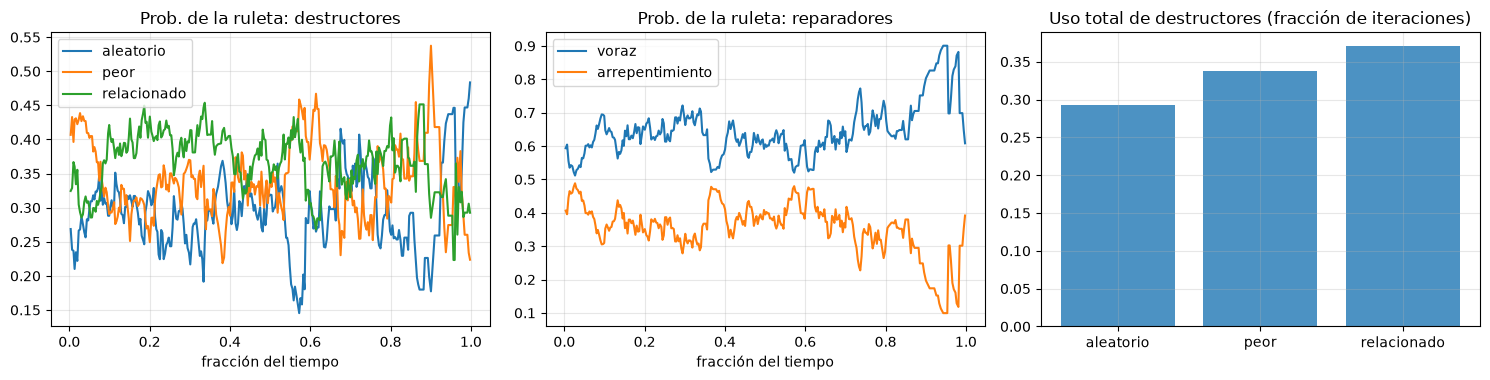

Uso total destructores: {'aleatorio': 4451, 'peor': 5141, 'relacionado': 5640}
Uso total reparadores : {'voraz': 9717, 'arrepentimiento': 5515}
Iteraciones: 15232; mejor largo: 630.65


In [13]:
P60 = TSP(60, seed=7)
t60, L60, h60, info = alns(P60, np.random.default_rng(1), 3.0)
assert es_tour(P60, t60)
tw = info["traza_w"]
frac = [x[1] for x in tw]
Wd = np.array([x[2] for x in tw]); Wr = np.array([x[3] for x in tw])

fig, axs = plt.subplots(1, 3, figsize=(15, 3.9))
for k, nm in enumerate(info["nd"]):
    axs[0].plot(frac, Wd[:, k], label=nm)
axs[0].set_title("Prob. de la ruleta: destructores"); axs[0].set_xlabel("fracción del tiempo"); axs[0].legend()
for k, nm in enumerate(info["nr"]):
    axs[1].plot(frac, Wr[:, k], label=nm)
axs[1].set_title("Prob. de la ruleta: reparadores"); axs[1].set_xlabel("fracción del tiempo"); axs[1].legend()
axs[2].bar(info["nd"], info["uso_d"] / info["uso_d"].sum(), alpha=0.8, label="destructores")
axs[2].set_title("Uso total de destructores (fracción de iteraciones)")
plt.tight_layout(); plt.show()

print("Uso total destructores:", {k: int(v) for k, v in zip(info["nd"], info["uso_d"])})
print("Uso total reparadores :", {k: int(v) for k, v in zip(info["nr"], info["uso_r"])})
print(f"Iteraciones: {info['iteraciones']}; mejor largo: {L60:.2f}")

Las probabilidades se alejan del reparto uniforme inicial: revisa en el gráfico qué operadores ganan probabilidad (en las ejecuciones que hicimos al escribir esto, la ruleta tendía a favorecer al destructor *relacionado* y al reparador *voraz*, pero como la corrida depende del reloj, el detalle cambia entre ejecuciones).
Pero las curvas son ruidosas (el puntaje por segmento depende de muy pocos eventos de mejora) y el piso de $10^{-3}$ en los pesos evita que un operador desaparezca por mala suerte.
Ten cuidado al interpretar: que un operador reciba más probabilidad no prueba que sea *mejor*, sino que puntuó más *en las fases en que se usó*;
además los operadores se eligen en pareja y el crédito se reparte entre ambos. Con otra semilla la ruleta puede favorecer otros operadores.

## 9. Comparación empírica sobre TSP

### Diseño experimental
- **Instancias**: 3 instancias euclídeas aleatorias con $n=60$, semillas distintas.
- **Corridas**: 5 semillas del algoritmo por instancia → 15 corridas por método.
- **Presupuesto**: igual **tiempo de reloj** para todos (1.5 s por corrida), de modo que se compare calidad a costo computacional equiparable.
- **Métodos**: reinicio aleatorio + 2-opt (línea base), Basic VNS, GVNS, LNS clásico (aleatorio + voraz), ALNS.
- **Métrica**: brecha relativa (%) respecto del mejor largo observado en esa instancia entre *todas* las corridas de *todos* los métodos (no conocemos el óptimo; es una cota superior de él).
  Reportamos media ± desviación estándar sobre las 15 corridas.

In [14]:
METODOS = {
    "Reinicio aleatorio + 2-opt": multistart_2opt,
    "Basic VNS": basic_vns,
    "GVNS": gvns,
    "LNS (aleatorio + voraz)": lns_clasico,
    "ALNS": alns_completo,
}
N_INST, N_SEM, PRES = 3, 5, 1.5
instancias = [TSP(60, seed=100 + s) for s in range(N_INST)]

resultados = []            # (método, instancia, semilla, largo)
historias = {m: [[] for _ in range(N_INST)] for m in METODOS}
c0 = time.perf_counter()
for ii, P in enumerate(instancias):
    for nombre, f in METODOS.items():
        for s in range(N_SEM):
            rng = np.random.default_rng(1000 * ii + s)       # misma semilla para todos los métodos
            out = f(P, rng, PRES)
            t, L, h = out[0], out[1], out[2]
            assert es_tour(P, t) and abs(P.largo(t) - L) < 1e-6
            resultados.append((nombre, ii, s, L))
            historias[nombre][ii].append(h)
print(f"Tiempo total de los experimentos: {time.perf_counter() - c0:.0f} s")
df = pd.DataFrame(resultados, columns=["metodo", "inst", "sem", "largo"])
mejor_inst = df.groupby("inst")["largo"].min()
df["brecha_%"] = 100 * (df["largo"] / df["inst"].map(mejor_inst) - 1)

resumen = df.groupby("metodo")["brecha_%"].agg(["mean", "std", "min", "max"])
resumen["n_corridas"] = df.groupby("metodo").size()
resumen = resumen.loc[list(METODOS)]
resumen.columns = ["brecha media %", "desv. est. %", "mín %", "máx %", "corridas"]
print(resumen.round(2).to_string())

Tiempo total de los experimentos: 113 s
                            brecha media %  desv. est. %  mín %  máx %  corridas
metodo                                                                          
Reinicio aleatorio + 2-opt            0.42          0.28    0.0   0.96        15
Basic VNS                             0.11          0.18    0.0   0.43        15
GVNS                                  0.05          0.10    0.0   0.38        15
LNS (aleatorio + voraz)               0.87          0.92    0.0   3.34        15
ALNS                                  0.33          0.53    0.0   1.63        15


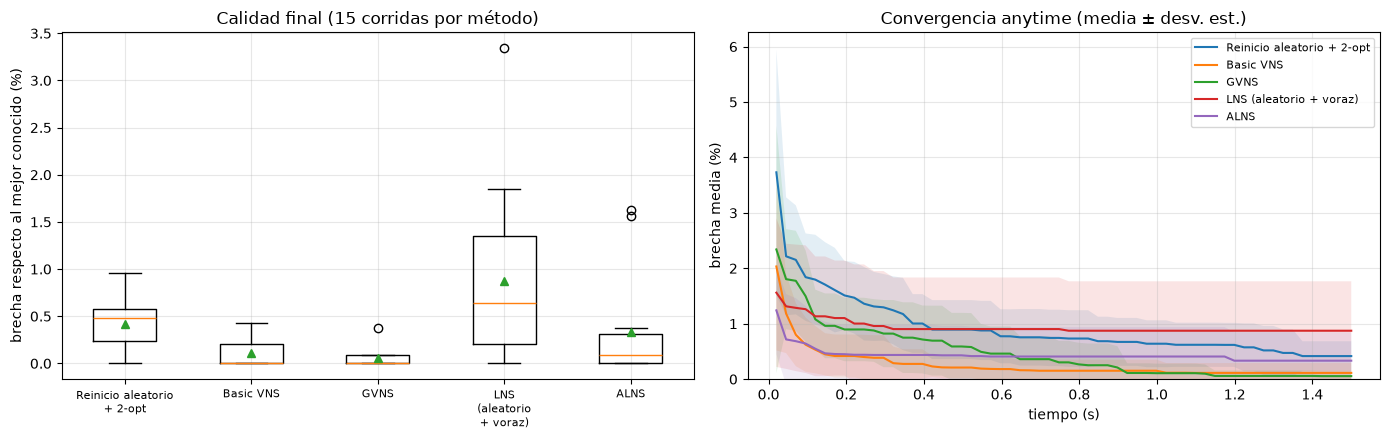

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
datos = [df[df.metodo == m]["brecha_%"].values for m in METODOS]
axs[0].boxplot(datos, showmeans=True)
axs[0].set_xticklabels([m.replace(" + ", "\n+ ").replace(" (", "\n(") for m in METODOS])
axs[0].set_ylabel("brecha respecto al mejor conocido (%)"); axs[0].set_title("Calidad final (15 corridas por método)")
axs[0].tick_params(axis="x", labelsize=8)

# convergencia anytime promediada: mejor largo vs tiempo, normalizado por el mejor de la instancia
grilla = np.linspace(0.02, PRES, 60)
def trayectoria(h, g):
    out = np.full(len(g), np.nan)
    for k, tt in enumerate(g):
        v = [L for (ts, L) in h if ts <= tt]
        out[k] = v[-1] if v else np.nan
    return out
for m in METODOS:
    curvas = []
    for ii in range(N_INST):
        for h in historias[m][ii]:
            curvas.append(100 * (trayectoria(h, grilla) / mejor_inst[ii] - 1))
    C = np.array(curvas)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)      # al inicio algunas corridas aún no tienen solución
        mu, sd = np.nanmean(C, 0), np.nanstd(C, 0)
    axs[1].plot(grilla, mu, label=m)
    axs[1].fill_between(grilla, mu - sd, mu + sd, alpha=0.12)
axs[1].set_xlabel("tiempo (s)"); axs[1].set_ylabel("brecha media (%)"); axs[1].set_ylim(0, None)
axs[1].set_title("Convergencia anytime (media ± desv. est.)"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### ¿Las diferencias son estadísticamente creíbles?

Las corridas están **pareadas** (misma instancia y misma semilla para cada método), así que usamos la prueba de rangos con signo de Wilcoxon sobre las 15 diferencias
de brecha entre pares de métodos. Es una verificación orientativa (15 pares, no independientes del todo porque comparten instancias), no una demostración.

In [16]:
piv = df.pivot_table(index=["inst", "sem"], columns="metodo", values="brecha_%")[list(METODOS)]
nombres = list(METODOS)
filas = []
for a, b in itertools.combinations(nombres, 2):
    dif = piv[a] - piv[b]
    if np.allclose(dif, 0):
        p = 1.0
    else:
        p = stats.wilcoxon(piv[a], piv[b]).pvalue
    filas.append((a, b, dif.mean(), p))
tabla_w = pd.DataFrame(filas, columns=["A", "B", "dif. media de brecha (A−B, % puntos)", "p Wilcoxon"])
tabla_w["¿p < 0.05?"] = tabla_w["p Wilcoxon"] < 0.05
print(tabla_w.round(4).to_string(index=False))
rank = piv.rank(axis=1).mean().loc[nombres]
print("\nRango medio por método (1 = mejor):")
print(rank.round(2).to_string())

                         A                       B  dif. media de brecha (A−B, % puntos)  p Wilcoxon  ¿p < 0.05?
Reinicio aleatorio + 2-opt               Basic VNS                                0.3034      0.0026        True
Reinicio aleatorio + 2-opt                    GVNS                                0.3614      0.0001        True
Reinicio aleatorio + 2-opt LNS (aleatorio + voraz)                               -0.4575      0.1688       False
Reinicio aleatorio + 2-opt                    ALNS                                0.0830      0.1876       False
                 Basic VNS                    GVNS                                0.0581      0.7774       False
                 Basic VNS LNS (aleatorio + voraz)                               -0.7608      0.0100        True
                 Basic VNS                    ALNS                               -0.2204      0.3783       False
                      GVNS LNS (aleatorio + voraz)                               -0.8189      0.

### Lectura honesta de los resultados

Qué se puede concluir y qué no, verificando contra las tablas y gráficos de arriba (15 corridas por método, 3 instancias de $n=60$, 1.5 s). Como el presupuesto es de **tiempo de reloj**,
los números exactos cambian un poco entre ejecuciones y máquinas; por eso solo afirmamos lo que se mantiene con holgura:
- **Basic VNS y GVNS** quedan al frente, y entre ellos **no** hay diferencia estadísticamente distinguible (p de Wilcoxon alto). Ambos superan de forma significativa a los reinicios aleatorios: una vez que se tiene un buen óptimo local, perturbarlo es más rentable que empezar de cero.
- **LNS clásico** (aleatorio + voraz con criterio tipo recocido) queda por detrás de la familia VNS y no se distingue del reinicio aleatorio: sus iteraciones son caras (reparar = constructivo) y, sin búsqueda local, el sesgo hacia soluciones buenas es débil con 1.5 s.
- **ALNS** tiende a quedar entre LNS clásico y VNS (la ventaja sobre LNS está en el borde de la significancia con 15 pares: revisa su p de Wilcoxon antes de afirmar nada). En el gráfico de convergencia, LNS y ALNS se aplanan hacia la segunda mitad del presupuesto porque la temperatura de aceptación decae con el tiempo.
- Estas conclusiones son para TSP euclídeo pequeño, vecindarios 2-opt/or-opt/3-opt en Python puro y presupuesto corto. El orden suele cambiar con $n$ mayor, con restricciones adicionales (donde LNS/ALNS brillan porque el reparador respeta la factibilidad) y con implementaciones compiladas. Es una comparación honesta, no un ranking universal.

## 10. Ventajas, limitaciones, resumen

### Ventajas y limitaciones

| Método | Ventajas | Limitaciones |
|---|---|---|
| **VND** | Determinista, sin parámetros salvo el orden de vecindarios; óptimo local respecto a varios vecindarios | Se queda atascado en el primer óptimo común a todos los vecindarios |
| **Basic VNS / GVNS** | Pocos parámetros ($k_{\max}$); diversificación gradual y controlada; fácil de implementar sobre código de búsqueda local existente | La búsqueda local domina el costo; el shaking aleatorio puede ser poco informado; sensible a $k_{\max}$ y a la definición de $\mathcal{N}_k$ |
| **LNS** | Vecindarios enormes que atraviesan barreras que 2-opt no cruza; natural para problemas con restricciones (rutas, asignación) donde el reparador respeta la factibilidad | Requiere diseñar operadores destruir/reparar; cada iteración es costosa (reparar es un constructivo) |
| **ALNS** | Autoconfigura la mezcla de operadores; flexible: se pueden agregar operadores sin rediseñar | Más parámetros ($\sigma_i,\rho,\theta$, $q$, $T$); los pesos son ruidosos con pocas iteraciones; el crédito se asigna a parejas de operadores |

### Resumen
- Un óptimo local siempre es relativo a un vecindario; cambiar de vecindario es una forma barata de escapar (VND).
- Los deltas incrementales hacen que evaluar un vecino cueste $O(1)$; verificarlos contra la recomputación es indispensable para no introducir errores silenciosos.
- VNS agrega **shaking** de intensidad creciente ($k$) y vuelve a $k=1$ al mejorar; GVNS usa VND como búsqueda local.
- LNS reemplaza el movimiento pequeño por *destruir + reparar*; ALNS elige los operadores por ruleta con pesos que se actualizan con puntajes por segmento.
- Las comparaciones requieren múltiples instancias y semillas, presupuesto equivalente y estadísticos (media ± desviación, pruebas pareadas), no una sola corrida.

Siguiente paso: [05 Aleatorizados y recocido simulado](05-aleatorizados-recocido-simulado.ipynb) generaliza el criterio de aceptación que usamos en LNS.
Para otros enfoques con memoria, ver [06 Búsqueda tabú](../02-metodos-con-memoria/06-busqueda-tabu.ipynb).

## Ejercicios propuestos

1. **2-opt con listas de vecinos**: agrega al VND una variante de 2-opt restringida a aristas entre ciudades cercanas (por ejemplo, las 8 más próximas) y mide su efecto sobre tiempo y calidad.
2. **Shaking alternativo**: reemplaza los $k$ swaps por $k$ *double-bridges* o por $k$ intercambios de segmentos. Repite `diagnostico_shaking`. ¿Cambia la probabilidad de volver al mismo óptimo?
3. **Skewed VNS**: acepta $x''$ si $f(x'')<f(x)+\alpha\,\delta(x,x'')$, donde $\delta$ es el número de aristas distintas. Compara con GVNS.
4. **RVNS**: implementa VNS reducido (sin búsqueda local) y compáralo en instancias con $n=200$.
5. **Operador nuevo para ALNS**: implementa un destructor por *tramo contiguo* (quitar $q$ ciudades consecutivas del tour) y un reparador por inserción del vecino más cercano; observa si la ruleta aprende a usarlos.
6. **Sensibilidad**: varía $\rho\in\{0,0.05,0.1,0.3,1\}$ y $\theta\in\{10,50,200\}$ en ALNS con semillas múltiples. ¿Qué pasa con $\rho=0$ (sin aprendizaje)?
7. **Demostración**: prueba que el tamaño del vecindario 2-opt (sin movimientos degenerados) es $n(n-3)/2$.

## Referencias

- Mladenović, N. y Hansen, P. (1997). *Variable neighborhood search*. Computers & Operations Research, 24(11).
- Hansen, P., Mladenović, N. y Pérez, J. A. M. (2010). *Variable neighbourhood search: methods and applications*. Annals of Operations Research, 175.
- Shaw, P. (1998). *Using constraint programming and local search methods to solve vehicle routing problems*. Principles and Practice of Constraint Programming (CP-98).
- Ropke, S. y Pisinger, D. (2006). *An adaptive large neighborhood search heuristic for the pickup and delivery problem with time windows*. Transportation Science, 40(4).
- Pisinger, D. y Ropke, S. (2010). *Large neighborhood search*. En Handbook of Metaheuristics (Gendreau y Potvin, eds.), 2.ª ed., Springer.
- Croes, G. A. (1958). *A method for solving traveling-salesman problems*. Operations Research, 6(6).
- Or, I. (1976). *Traveling salesman-type combinatorial problems and their relation to the logistics of regional blood banking*. Tesis doctoral, Northwestern University.